# Предсказание цен на недвижимость

**Задача:** предсказать цену объявления в городе N. **Метрика:** MAE в рублях, `score = 1 / (1 + MAE)`.

**На выходе:** файл `submission.csv` рядом с ноутбуком. Данные лежат в папке `data/`.

Что определило решение:

1. **Разбиение по времени лексикографическое.** Даты отсортированы как строки, поэтому в train попали 2012-10…12, а в test — 2012-3…9 и весь 2013 год. Месяцы 2012-4…9 надо интерполировать, 2013-й — экстраполировать.
2. **Деревья не экстраполируют.** Поэтому тренд вынесен из модели: бустинг учится на цене без тренда, а тренд добавляется к прогнозу отдельно. Уровень 2013 года по train проверить нельзя, поэтому он уточнён по публичному лидерборду (раздел 6).
3. **Около 4% цен — заглушка ровно 1 000 000.** Эти строки неотличимы от остальных по признакам, поэтому из обучения они убраны, а их наличие в тесте учтено сдвигом прогноза.
4. **Цель — лог цены за м² за вычетом уровня улицы.** Это дало самый большой прирост качества.

In [1]:
import os
import time
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from catboost import CatBoostRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")

DATA_DIR = "data"
PLACEHOLDER_PRICE = 1_000_000  # цена-заглушка
DAMPING = 0.8                  # затухание тренда, выбрано на бэктесте
STREET_PRIOR = 5               # сглаживание уровня улицы
SEEDS = [0, 1, 2]
LB_SHIFT_JAN_2013 = 0.02       # поправка лог-цены на январь 2013, подобрана по public
LB_SHIFT_PER_MONTH = 0.10 / 11 # её рост за месяц в течение 2013 года
N_JOBS = min(16, os.cpu_count())

LGB_PARAMS = dict(
    objective="quantile", alpha=0.5, n_estimators=3000, learning_rate=0.02,
    num_leaves=63, min_child_samples=20, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.7, verbose=-1, n_jobs=N_JOBS,
)
CAT_PARAMS = dict(
    iterations=3000, learning_rate=0.05, depth=6, loss_function="MAE",
    verbose=False, thread_count=N_JOBS, allow_writing_files=False,
)

## 1. Данные

Дата переводится в номер месяца `t` (0 = январь 2011). Это наглядно показывает разрыв: в train нет месяцев 15–20.

In [2]:
def add_month_index(df):
    year_month = df["date"].str.split("-", expand=True).astype(int)
    df["t"] = (year_month[0] - 2011) * 12 + year_month[1] - 1
    return df


train = add_month_index(pd.read_csv(f"{DATA_DIR}/train.csv"))
test = add_month_index(pd.read_csv(f"{DATA_DIR}/test.csv"))
sample = pd.read_csv(f"{DATA_DIR}/sample_submission.csv")

train["log_price"] = np.log(train["price"])
train["clean"] = train["price"] != PLACEHOLDER_PRICE

print(f"train {train.shape}, test {test.shape}")
print("месяцы train:", sorted(train["t"].unique().tolist()))
print("месяцы test: ", sorted(test["t"].unique().tolist()))
print(f"доля заглушек: {1 - train['clean'].mean():.2%}")

train (100000, 28), test (100000, 25)
месяцы train: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 21, 22, 23]
месяцы test:  [14, 15, 16, 17, 18, 19, 20, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35]
доля заглушек: 4.08%


Проверим, что заглушки действительно случайны: средние значения признаков в обеих группах должны совпадать.

In [3]:
cols = ["area", "rooms", "floor", "balcon", "metro_dist", "n_photos", "t"]
train.groupby("clean")[cols].mean().round(2)

,area,rooms,floor,balcon,metro_dist,n_photos,t
clean,,,,,,,
False,52.50,2.12,5.33,0.4,22.03,2.47,9.47
True,52.24,2.12,5.26,0.4,22.16,2.47,9.49


## 2. Признаки

Важно, что `street_id` не подаётся в модель как категория. Вместо этого используются:

- **`s_lvl`** — сглаженная медиана цены за м² по улице, она же вычитается из цели;
- **числовые агрегаты улицы** (`s_*`) — посчитаны по train и test без использования цен. Абляция показала, что они взаимозаменяемы: деревья используют их как числовой идентификатор улицы и находят зависимости, свойственные конкретным улицам.

In [4]:
street_stats = (
    pd.concat([train, test], ignore_index=True)
    .groupby("street_id")
    .agg(
        s_area=("area", "mean"),
        s_floor=("floor", "mean"),
        s_fmax=("floor", "max"),
        s_metro=("metro_dist", "mean"),
        s_b0=("build_tech", lambda s: (s == 0).mean()),
        s_b1=("build_tech", lambda s: (s == 1).mean()),
        s_b2=("build_tech", lambda s: (s == 2).mean()),
        s_bal=("balcon", "mean"),
        s_ph=("n_photos", "mean"),
    )
)


def add_features(df):
    df = df.join(street_stats, on="street_id")
    df["area_per_room"] = df["area"] / df["rooms"]
    # Балкон 1 или 2 указывает на такой же build_tech, этим заполняем пропуски
    df["build_filled"] = df["build_tech"].fillna(df["balcon"].where(df["balcon"] > 0))
    df["first_floor"] = (df["floor"] == 1).astype(int)
    return df


train, test = add_features(train), add_features(test)

KEYWORDS = [f"kw{i}" for i in range(1, 14)]
FEATURES = (
    ["build_tech", "floor", "area", "rooms", "balcon", "metro_dist", "g_lift", "n_photos"]
    + KEYWORDS + ["area_per_room", "build_filled", "first_floor"]
    + list(street_stats.columns) + ["s_lvl"]
)

## 3. Тренд цен

Индекс цен — это коэффициенты при месяцах в аддитивной модели логарифма цены (улица, комнаты, тип дома, балкон, метро, площадь, этаж). В отличие от простой средней цены, он не зависит от того, какие квартиры продавались в конкретный месяц.

Внутри наблюдаемого периода индекс сглаживается и интерполируется, в том числе через разрыв. После него наклон последних 9 месяцев затухает с коэффициентом φ = 0.8.

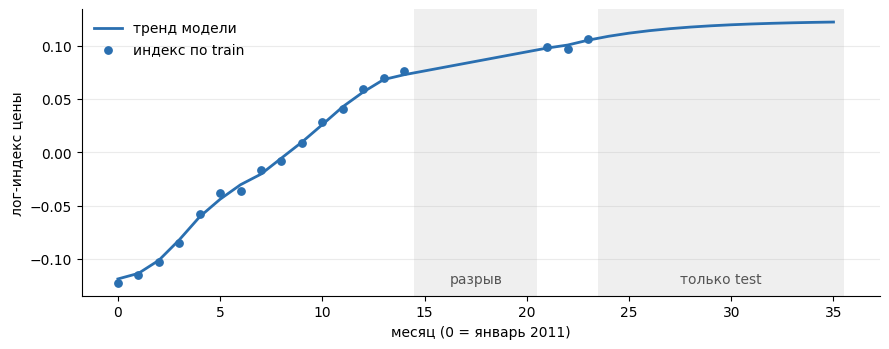

In [5]:
def fit_price_index(df):
    df = df[df["clean"]]
    categories = pd.DataFrame({
        "street": df["street_id"],
        "rooms": df["rooms"],
        "build": df["build_tech"].fillna(-1),
        "balcon": df["balcon"],
        "metro": df["metro_dist"].fillna(-1),
        "photos": df["n_photos"].clip(upper=9),
        "t": df["t"],
    })
    encoder = OneHotEncoder(handle_unknown="ignore")
    design = sp.hstack([
        encoder.fit_transform(categories),
        sp.csr_matrix(np.c_[np.log(df["area"]), np.log(df["floor"])]),
    ]).tocsr()
    model = Ridge(alpha=1e-3).fit(design, df["log_price"])
    months = encoder.categories_[-1]
    start = sum(len(c) for c in encoder.categories_[:-1])
    coefs = model.coef_[start:start + len(months)]
    return pd.Series(coefs - coefs.mean(), index=months)


def trend(index, months, damping=DAMPING):
    """Значение тренда для месяцев months: сглаженный индекс, затем затухание."""
    months = np.asarray(months, dtype=float)
    observed = index.index.values.astype(float)
    # Сглаживаем только внутри непрерывных отрезков, чтобы окно не перепрыгивало разрыв
    segments = (np.diff(observed, prepend=observed[0]) > 2).cumsum()
    smooth = index.groupby(segments).transform(
        lambda s: s.rolling(3, center=True, min_periods=1).mean()
    ).values
    anchor_t, anchor_v = observed[-3:].mean(), index.values[-3:].mean()
    slope = np.polyfit(observed[-9:], index.values[-9:], 1)[0]
    horizon = np.maximum(months - anchor_t, 0)
    damped_steps = horizon if damping == 1 else damping * (1 - damping ** horizon) / (1 - damping)
    future = anchor_v + slope * damped_steps
    return np.where(months <= anchor_t, np.interp(months, observed, smooth), future)


price_index = fit_price_index(train)
all_months = np.arange(36)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(all_months, trend(price_index, all_months), color="#2a6fb0", lw=2, label="тренд модели")
ax.scatter(price_index.index, price_index.values, color="#2a6fb0", s=28, zorder=3, label="индекс по train")
ax.axvspan(14.5, 20.5, color="#999999", alpha=0.15, lw=0)
ax.axvspan(23.5, 35.5, color="#999999", alpha=0.15, lw=0)
ax.text(17.5, price_index.min(), "разрыв", ha="center", color="#555555")
ax.text(29.5, price_index.min(), "только test", ha="center", color="#555555")
ax.set_xlabel("месяц (0 = январь 2011)")
ax.set_ylabel("лог-индекс цены")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

## 4. Модель

Цель: `log(цена) − тренд − log(площадь) − уровень улицы`. Функция потерь — L1, потому что медиана минимизирует MAE и не меняется при монотонном преобразовании, то есть логарифм не смещает прогноз.

Итоговый прогноз — среднее LightGBM и CatBoost в лог-шкале. На обучении используются только чистые строки.

In [6]:
def street_level(fit_df, log_ppm):
    """Медиана лог-цены за м² по улице, сглаженная к общей медиане."""
    grouped = pd.Series(log_ppm, index=fit_df.index).groupby(fit_df["street_id"])
    median, count = grouped.median(), grouped.size()
    return (median * count + np.median(log_ppm) * STREET_PRIOR) / (count + STREET_PRIOR)


def fit_predict(fit_df, pred_df, seeds, use_catboost=True):
    """Обучает модели на fit_df и возвращает лог-прогнозы LightGBM и CatBoost для pred_df."""
    index = fit_price_index(fit_df)
    fit_df = fit_df[fit_df["clean"]]

    log_ppm = (fit_df["log_price"] - trend(index, fit_df["t"]) - np.log(fit_df["area"])).values
    levels = street_level(fit_df, log_ppm)
    fit_level = fit_df["street_id"].map(levels).values
    pred_level = pred_df["street_id"].map(levels).fillna(levels.median()).values

    X_fit = fit_df.assign(s_lvl=fit_level)[FEATURES]
    X_pred = pred_df.assign(s_lvl=pred_level)[FEATURES]
    target = log_ppm - fit_level

    lgb_pred, cat_pred = np.zeros(len(pred_df)), np.zeros(len(pred_df))
    for seed in seeds:
        lgb_model = lgb.LGBMRegressor(**LGB_PARAMS, random_state=seed).fit(X_fit, target)
        lgb_pred += lgb_model.predict(X_pred) / len(seeds)
        if use_catboost:
            cat_model = CatBoostRegressor(**CAT_PARAMS, random_seed=seed).fit(X_fit, target)
            cat_pred += cat_model.predict(X_pred) / len(seeds)

    base = pred_level + np.log(pred_df["area"].values) + trend(index, pred_df["t"])
    return base + lgb_pred, base + cat_pred


def mae(log_pred, price):
    return np.abs(np.exp(log_pred) - price).mean()

## 5. Валидация

**Кросс-валидация по месяцам.** Случайные фолды здесь не подходят: почти все месяцы теста отсутствуют в обучении. Поэтому в каждом фолде целиком откладывается треть месяцев, а индекс цен для них восстанавливается только по остальным. MAE считается по всем строкам, включая заглушки, как и на лидерборде.

In [7]:
started = time.time()
oof_lgb, oof_cat = np.zeros(len(train)), np.zeros(len(train))
for fold in range(3):
    held_out = (train["t"] % 3 == fold).values
    oof_lgb[held_out], oof_cat[held_out] = fit_predict(train[~held_out], train[held_out], seeds=[0])

oof_blend = (oof_lgb + oof_cat) / 2
clean = train["clean"].values
price = train["price"].values
print(f"время валидации: {time.time() - started:.0f} c")
pd.DataFrame(
    {
        "MAE, все строки": [mae(p, price) for p in (oof_lgb, oof_cat, oof_blend)],
        "MAE, без заглушек": [mae(p[clean], price[clean]) for p in (oof_lgb, oof_cat, oof_blend)],
    },
    index=["LightGBM", "CatBoost", "Смесь"],
).round(0).astype(int)

время валидации: 74 c


,"MAE, все строки","MAE, без заглушек"
LightGBM,533599,370523
CatBoost,531352,368328
Смесь,530317,367187


**Сдвиг на заглушки.** В тесте тоже есть ~4% заглушек, и они почти всегда ниже прогноза. Поэтому минимум MAE достигается не на медиане чистых цен, а немного ниже неё. Сдвиг подбирается по OOF-прогнозам.

In [8]:
shifts = np.arange(-0.03, 0.0101, 0.0025)
shift_mae = [mae(oof_blend + s, price) for s in shifts]
SHIFT = float(shifts[int(np.argmin(shift_mae))])
print(f"лучший сдвиг {SHIFT:+.4f}: MAE {min(shift_mae):,.0f} (без сдвига {mae(oof_blend, price):,.0f})")

лучший сдвиг -0.0025: MAE 530,013 (без сдвига 530,317)


**Бэктест тренда.** Обучаемся на прошлом и предсказываем будущее, как в настоящей задаче. Для сравнения способов продления тренда достаточно LightGBM: меняется только добавка тренда к одному и тому же прогнозу. φ = 0 означает плоское продление, φ = 1 — линейное.

In [9]:
rows = []
for cut, start in [(11, 12), (14, 21)]:
    fit_df, pred_df = train[train["t"] <= cut], train[train["t"] >= start]
    index = fit_price_index(fit_df)
    log_pred, _ = fit_predict(fit_df, pred_df, seeds=[0], use_catboost=False)
    without_trend = log_pred - trend(index, pred_df["t"])
    for damping in (0, 0.8, 0.9, 1):
        log_pred = without_trend + trend(index, pred_df["t"], damping)
        rows.append({"обучение до t": cut, "φ": damping, "MAE": mae(log_pred, pred_df["price"].values)})

pd.DataFrame(rows).pivot(index="φ", columns="обучение до t", values="MAE").round(0).astype(int)

обучение до t,11,14
φ,,
0.0,657271,605967
0.8,581713,592860
0.9,584812,653017
1.0,727813,858973


## 6. Итоговая модель и submission

Обучаемся на всём train с тремя сидами и применяем найденный сдвиг.

**Поправка на 2013 год.** В train нет ни одного месяца 2013 года, а бэктест на 2011–2012 годах подсказал затухание тренда. На лидерборде это не подтвердилось: первая посылка дала MAE около 724 тыс. Чтобы найти причину, цены 2013 года в посылках меняли, а остальные оставляли как есть:

| Поправка | Public MAE, руб. |
|---|---|
| 2013 год × 0.90 | 1 016 886 |
| без поправки | 723 751 |
| 2013 год × 1.10 | 661 475 |
| 2013 год × 1.07 | 646 566 |
| 2013 год: лог-поправка от 0.00 до 0.15 | 629 377 |
| 2013 год: лог-поправка от 0.02 до 0.13, цены 2012 года −2% | 630 518 |
| 2013 год: лог-поправка от 0.02 до 0.13, цены 2012 года +2% | 628 164 |
| 2013 год: лог-поправка от 0.02 до 0.13 | ≈ 625 700 |
| **2013 год: лог-поправка от 0.02 до 0.12** | **624 593** |

Выводы: рост цен в 2013 году возобновился, поэтому нарастающая поправка лучше постоянной, а уровень месяцев 2012 года менять не нужно. В ноутбуке используется лучший вариант. Это два параметра, подобранных по public. Public — случайные 30% теста, поэтому сильное переобучение маловероятно, но независимой проверки у поправки нет.

Дальнейшие попытки не улучшили кросс-валидацию заметно: другие настройки CatBoost, случайные коды улиц, статистики улиц по ценам, ExtraTrees и линейная модель в смеси дали меньше 200 руб. Отдельно проверено на бэктесте, что рост равномерный по цене, числу комнат и типу дома, а изменения уровня улиц в будущее не переносятся.

In [10]:
started = time.time()
log_lgb, log_cat = fit_predict(train, test, seeds=SEEDS)
months_2013 = test["t"].values - 24
lb_shift = np.where(months_2013 >= 0, LB_SHIFT_JAN_2013 + LB_SHIFT_PER_MONTH * months_2013, 0.0)
prediction = np.exp((log_lgb + log_cat) / 2 + SHIFT + lb_shift)

submission = pd.DataFrame({"id": test["id"], "price": prediction.round(2)})
assert submission["id"].equals(sample["id"])
assert submission["price"].notna().all() and (submission["price"] > 0).all()
submission.to_csv("submission.csv", index=False)

print(f"submission.csv сохранён за {time.time() - started:.0f} c, строк: {len(submission)}")
print(submission["price"].describe().round(0).to_string())
print("медиана цены в train без заглушек:", train.loc[train["clean"], "price"].median())

submission.csv сохранён за 108 c, строк: 100000
count       100000.0
mean       6166515.0
std        4895104.0
min         581902.0
25%        3306544.0
50%        4911523.0
75%        7391282.0
max      114267642.0
медиана цены в train без заглушек: 4223000.0
